# Loaded dice 

Welcome to the second assignment in the course Probability and Statistics for Machine Learning and Data Science! In this quiz-like assignment you will test your intuition about the concepts covered in the lectures by taking the example with the dice to the next level. 

**This assignment can be completed with just pencil and paper, or even your intuition about probability, but in many questions using the skills you're developing as a programmer may help**. 

## 1 - Introduction

You will be presented with 11 questions regarding a several dice games. Sometimes the dice is loaded, sometimes it is not. You will have clear instructions for each exercise.

### 1.1 How to go through the assignment

In each exercise you there will be a question about throwing some dice that may or may not be loaded. You will have to answer questions about the results of each scenario, such as calculating the expected value of the dice throw or selecting the graph that best represents the distribution of outcomes. 

In any case, **you will be able to solve the exercise with one of the following methods:**

- **By hand:** You may make your calculations by hand, using the theory you have developed in the lectures.
- **Using Python:** You may use the empty block of code provided to make computations and simulations, to obtain the result.

After each exercise you will save your solution by running a special code cell and adding your answer. The cells contain a single line of code in the format `utils1`.exercise_1()` which will launch the interface in which you can save your answer. **You will save your responses to each exercise as you go, but you won't submit all your responses for grading until you submit this assignment at the end.**

Let's go over an example! Before, let's import the necessary libraries.

## 2 - Importing the libraries

In [20]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import utils1

## 3 - A worked example on how to complete this assignment.

Now let's go over one example question, so you understand how to go through the assignment.

### 3.1 Example question

Question: Given a 6-sided fair dice, you throw it two times and save the result. What is the probability that the sum of your two throws is greater than 5? (Give your result with 1 decimal place).

After the question, you will see the following block of code.

In [21]:
# 定义期望的面数 (你可以尝试修改这个数值！)
n_sides = 6
# 使用 numpy 数组表示一枚骰子
dice = np.array([i for i in range(1, n_sides + 1)])

n_rolls = 20000

# 第一次投掷
first_rolls = np.array([np.random.choice(dice) for _ in range(n_rolls)])
# 第二次投掷
second_rolls = np.array([np.random.choice(dice) for _ in range(n_rolls)])
sum_of_rolls = first_rolls + second_rolls
answer = sum_of_rolls[sum_of_rolls > 5].size / sum_of_rolls.size
# 小数点保留两位
print(f"{answer:.2f}")


# loaded_number：你想作弊的那一面（比如你想让 6 点出现的概率翻倍，就传入 6）
def load_dice(n_sides, loaded_number):

    # 初始状态下所有面的概率均等
    probs = np.array([1 / (n_sides + 1) for _ in range(n_sides)])

    # 将特定面的概率设为其她面的两倍
    probs[loaded_number - 1] = 1 - sum(probs[:-1])

    # 验证所有概率之和是否为 1
    if not np.isclose(sum(probs), 1):
        print("All probabilities should add up to 1")
        return

    return probs


0.72


In [22]:
# 小于等于5的情况 1,1 1,2 1,3 1,4 2,1 2,2 2,3 3,1 3,2 4,1 一共 10 种  10/36 ≈ 0.28
# 所以大于5的情况是 36 - 10 = 26 种  26/36 ≈ 0.72
# You can use this cell for your calculations (not graded)
0.72

0.72

You may use it as you wish to solve the exercise. Or you can just ignore it and use pencil and pen to solve. It is up to you! **You will only save your final answer**. 

### 3.2 Solving using simulations in Python

Let's solve this question in both ways. First, using Python. You may check the ungraded lab Dice Simulations that appears right before this assignment to help you simulate dice throws. Remember that, to get a good approximation, you need to simulate it a lot of times! You will see why this is true in the following weeks, but this is quite intuitive.

In [23]:
# You can use this cell for your calculations (not graded)

# This list represents each dice side
dice = [1, 2, 3, 4, 5, 6]

# The idea is to randomly choose one element from this list three times and sum them.
# Each time we choose, it is as if we had thrown a dice and the side is the chosen number.
# This list will store the sum for each iteration. The idea is to repeat this experiment several times.
sum_results = []

number_iterations = 1000

# Setting a random seed just for reproducibility
np.random.seed(42)
# It will play this game number_iteration times
for i in range(number_iterations):
    # Throw the first dice
    throw_1 = np.random.choice(dice)
    # Throw the second dice
    throw_2 = np.random.choice(dice)
    # Sum the result
    sum_throw = throw_1 + throw_2
    # Append to the sum_result list
    sum_results.append(sum_throw)

# After recording all the sums, the actual probability will be very close to the proportion among every sum greater than 10 in the sum_results list.
greater_5_count = 0

for x in sum_results:
    if x > 5:
        greater_5_count += 1

probability = greater_5_count / len(sum_results)
print(f"The probability by this simulation is: {probability}")

The probability by this simulation is: 0.719


So the result you would get, rounding in to decimal place, would be 0.7! Let's solve it "by hand".

### 3.3 Solving using the theory

When throwing two dice, there are $36$ possible outcomes:

$$(1,1), (1,2), \ldots, (6,6)$$

You must count how many of them lead to a sum greater than 5. They are:

* If the first throw is $1$, there are $2$ possibilities for the second throw: 5 or 6.
* If the first throw is $2$, there are $3$ possibilities for the second throw: 4, 5 or 6.
* If the first throw is $3$, there are $4$ possibilities for the second throw: 3, 4, 5 or 6.
* If the first throw is $4$, there are $5$ possibilities for the second throw: 2, 3, 4, 5 or 6.
* If the first throw is $5$, there are $6$ possibilities for the second throw: 1, 2, 3, 4, 5 or 6.
* If the first throw is $6$, there are $6$ possibilities for the second throw: 1, 2, 3, 4, 5 or 6.

So, in total there are $2 + 3 + 4 + 5 + 6 + 6 = 26$, possibilities that sum greater than 5.

The probability is then $\frac{26}{36} \approx 0.72$. Rounding it to 1 decimal place, the result is also 0.7!


### 3.4 Saving your answer

Once you get your answer in hands, it is time to save it. Run the next code below to see what it will look like. You just add your answer as requested and click on "Save your answer!"

In [24]:
utils1.exercise_example()

FloatText(value=0.0, description='Probability:')

Button(button_style='success', description='Save your answer!', style=ButtonStyle())

Output()

And that's it! Once you save one question, you can go to the next one. If you want to change your solution, just run the code again and input the new solution, it will overwrite the previous one. At the end of the assignment, you will be able to check if you have forgotten to save any question. 

Once you finish the assignment, you may submit it as you usually would. Your most recently save answers to each exercise will then be graded.

## 4 - Some concept clarifications 🎲🎲🎲

During this assignment you will be presented with various scenarios that involve dice. Usually dice can have different numbers of sides and can be either fair or loaded.

- A fair dice has equal probability of landing on every side.
- A loaded dice does not have equal probability of landing on every side. Usually one (or more) sides have a greater probability of showing up than the rest.

Alright, that's all your need to know to complete this assignment. Time to start rolling some dice!

## Exercise 1:



Given a 6-sided fair dice (all of the sides have equal probability of showing up), compute the mean and variance for the probability distribution that models said dice. The next figure shows you a visual represenatation of said distribution:

<img src="./images/fair_dice.png" style="height: 300px;"/>

**Submission considerations:**
- Submit your answers as floating point numbers with three digits after the decimal point
- Example: To submit the value of 1/4 enter 0.250

Hints: 
- You can use [np.random.choice](https://numpy.org/doc/stable/reference/random/generated/numpy.random.choice.html) to simulate a fair dice.
- You can use [np.mean](https://numpy.org/doc/stable/reference/generated/numpy.mean.html) and [np.var](https://numpy.org/doc/stable/reference/generated/numpy.var.html) to compute the mean and variance of a numpy array.

In [25]:
# You can use this cell for your calculations (not graded)
# 定义期望的面数 (你可以尝试修改这个数值！)
n_sides = 6
# 使用 numpy 数组表示一枚骰子
dice = np.array([i for i in range(1, n_sides + 1)])

n_rolls = 20000

# 第一次投掷
first_rolls = np.array([np.random.choice(dice) for _ in range(n_rolls)])
mean = first_rolls.mean()
var = first_rolls.var()
# 小数点保留两位
print(f"Mean: {mean:.3f}")
print(f"Variance: {var:.3f}")


Mean: 3.498
Variance: 2.922


In [26]:
# Run this cell to submit your answer
utils1.exercise_1()

FloatText(value=0.0, description='Mean:')

FloatText(value=0.0, description='Variance:')

Button(button_style='success', description='Save your answer!', style=ButtonStyle())

Output()

## Exercise 2:

Now suppose you are throwing the dice (same dice as in the previous exercise) two times and recording the sum of each throw. Which of the following `probability mass functions` will be the one you should get?

<table><tr>
<td> <img src="./images/hist_sum_6_side.png" style="height: 300px;"/> </td>
<td> <img src="./images/hist_sum_5_side.png" style="height: 300px;"/> </td>
<td> <img src="./images/hist_sum_6_uf.png" style="height: 300px;"/> </td>
</tr></table>


Hints: 
- You can use numpy arrays to hold the results of many throws.
- You can sum to numpy arrays by using the `+` operator like this: `sum = first_throw + second_throw`
- To simulate multiple throws of a dice you can use list comprehension or a for loop

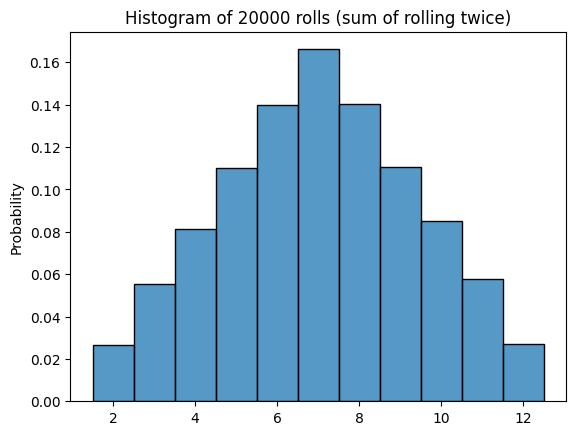

In [27]:
# You can use this cell for your calculations (not graded)
# 定义期望的面数 (你可以尝试修改这个数值！)
n_sides = 6
# 使用 numpy 数组表示一枚骰子
dice = np.array([i for i in range(1, n_sides + 1)])

n_rolls = 20000

# 第一次投掷
first_rolls = np.array([np.random.choice(dice) for _ in range(n_rolls)])
# 第二次投掷
second_rolls = np.array([np.random.choice(dice) for _ in range(n_rolls)])
sum_of_rolls = first_rolls + second_rolls

# 绘制直方图
sum_rolls_hist = sns.histplot(sum_of_rolls, stat="probability", discrete=True)
sum_rolls_hist.set(title=f"Histogram of {n_rolls} rolls (sum of rolling twice)")
plt.show()

In [28]:
# Run this cell to submit your answer
utils1.exercise_2()

ToggleButtons(description='Your answer:', options=('left', 'center', 'right'), value='left')

Button(button_style='success', description='Save your answer!', style=ButtonStyle())

Output()

## Exercise 3:

Given a fair 4-sided dice, you throw it two times and record the sum. The figure on the left shows the probabilities of the dice landing on each side and the right figure the histogram of the sum. Fill out the probabilities of each sum (notice that the distribution of the sum is symetrical so you only need to input 4 values in total):

<img src="./images/4_side_hists.png" style="height: 300px;"/>

**Submission considerations:**
- Submit your answers as floating point numbers with three digits after the decimal point
- Example: To submit the value of 1/4 enter 0.250

In [29]:
# You can use this cell for your calculations (not graded)
# 定义期望的面数 (你可以尝试修改这个数值！)
n_sides = 4
# 使用 numpy 数组表示一枚骰子
dice = np.array([i for i in range(1, n_sides + 1)])

n_rolls = 20000

# 第一次投掷
first_rolls = np.array([np.random.choice(dice) for _ in range(n_rolls)])
# 第二次投掷
second_rolls = np.array([np.random.choice(dice) for _ in range(n_rolls)])
sum_of_rolls = first_rolls + second_rolls

probabilities = np.bincount(sum_of_rolls)[2:] / n_rolls
# 保留三位小数
print(f"{probabilities.round(3)}")


[0.063 0.126 0.19  0.25  0.183 0.121 0.067]


In [30]:
# Run this cell to submit your answer
utils1.exercise_3()

FloatText(value=0.0, description='P for sum=2', style=DescriptionStyle(description_width='initial'))

FloatText(value=0.0, description='P for sum=3:', style=DescriptionStyle(description_width='initial'))

FloatText(value=0.0, description='P for sum=4:', style=DescriptionStyle(description_width='initial'))

FloatText(value=0.0, description='P for sum=5:', style=DescriptionStyle(description_width='initial'))

Button(button_style='success', description='Save your answer!', style=ButtonStyle())

Output()

## Exercise 4:

Using the same scenario as in the previous exercise. Compute the mean and variance of the sum of the two throws  and the covariance between the first and the second throw:

<img src="./images/4_sided_hist_no_prob.png" style="height: 300px;"/>


Hints:
- You can use [np.cov](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) to compute the covariance of two numpy arrays (this may not be needed for this particular exercise).

In [31]:
# You can use this cell for your calculations (not graded)
mean = np.mean(sum_of_rolls)
var = np.var(sum_of_rolls)
cov = np.cov(first_rolls, second_rolls)
print(f"Mean: {mean:.3f}")
print(f"Variance: {var:.3f}")
print(f"Covariance: {cov[0, 1]:.3f}")
print(cov)

Mean: 4.995
Variance: 2.531
Covariance: 0.011
[[1.25279208 0.01147661]
 [0.01147661 1.25515315]]


In [32]:
# Run this cell to submit your answer
utils1.exercise_4()

FloatText(value=0.0, description='Mean:')

FloatText(value=0.0, description='Variance:')

FloatText(value=0.0, description='Covariance:')

Button(button_style='success', description='Save your answer!', style=ButtonStyle())

Output()

## Exercise 5:


Now suppose you are have a loaded 4-sided dice (it is loaded so that it lands twice as often on side 2 compared to the other sides): 


<img src="./images/4_side_uf.png" style="height: 300px;"/>

You are throwing it two times and recording the sum of each throw. Which of the following `probability mass functions` will be the one you should get?

<table><tr>
<td> <img src="./images/hist_sum_4_4l.png" style="height: 300px;"/> </td>
<td> <img src="./images/hist_sum_4_3l.png" style="height: 300px;"/> </td>
<td> <img src="./images/hist_sum_4_uf.png" style="height: 300px;"/> </td>
</tr></table>

Hints: 
- You can use the `p` parameter of [np.random.choice](https://numpy.org/doc/stable/reference/random/generated/numpy.random.choice.html) to simulate a loaded dice.

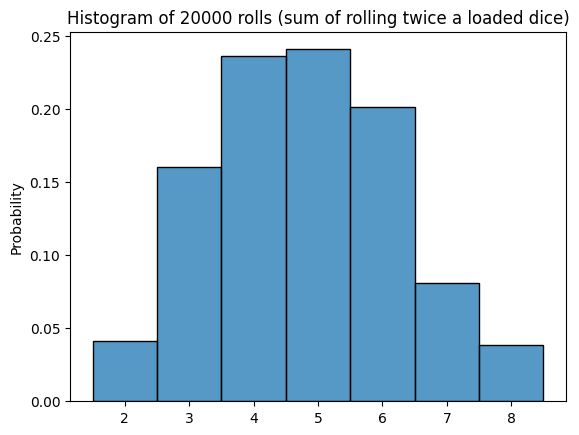

In [ ]:
# You can use this cell for your calculations (not graded)
n_sides = 4
probs_loaded_dice = load_dice(n_sides, loaded_number=2)

n_rolls = 20000
first_rolls = np.array(
    [np.random.choice(dice, p=probs_loaded_dice) for _ in range(n_rolls)]
)

second_rolls = np.array(
    [np.random.choice(dice, p=probs_loaded_dice) for _ in range(n_rolls)]
)

sum_of_rolls = first_rolls + second_rolls

loaded_rolls_hist = sns.histplot(sum_of_rolls, stat="probability", discrete=True)
loaded_rolls_hist.set(
    title=f"Histogram of {n_rolls} rolls (sum of rolling twice a loaded dice)"
)
loaded_rolls_hist.set_xticks(range(min(sum_of_rolls), max(sum_of_rolls) + 1))
plt.show()

In [ ]:
# Run this cell to submit your answer
utils1.exercise_5()

## Exercise 6:

You have a 6-sided dice that is loaded so that it lands twice as often on side 3 compared to the other sides:

<img src="./images/loaded_6_side.png" style="height: 300px;"/>

You record the sum of throwing it twice. What is the highest value (of the sum) that will yield a cumulative probability lower or equal to 0.5?

<img src="./images/loaded_6_cdf.png" style="height: 300px;"/>

Hints:
- The probability of side 3 is equal to $\frac{2}{7}$

In [ ]:
# You can use this cell for your calculations (not graded)
n_sides = 6
dice = np.array([i for i in range(1, n_sides + 1)])
probs_loaded_dice = load_dice(n_sides, loaded_number=3)

n_rolls = 20000
first_rolls = np.array(
    [np.random.choice(dice, p=probs_loaded_dice) for _ in range(n_rolls)]
)
second_rolls = np.array(
    [np.random.choice(dice, p=probs_loaded_dice) for _ in range(n_rolls)]
)
sum_of_rolls = first_rolls + second_rolls

# 满足累积概率 (Cumulative Probability) 小于或等于 0.5 的前提下，点数之和的最大可能值是多少？
cumulative_probabilities = np.cumsum(np.bincount(sum_of_rolls)[2:] / n_rolls)
max_value_under_half_cumulative = np.max(np.where(cumulative_probabilities <= 0.5)) + 2
print(
    f"Maximum sum under cumulative probability <= 0.5: {max_value_under_half_cumulative}"
)


Maximum sum under cumulative probability <= 0.5: 6


In [ ]:
# Run this cell to submit your answer
utils1.exercise_6()

## Exercise 7:

Given a 6-sided fair dice you try a new game. You only throw the dice a second time if the result of the first throw is **lower** or equal to 3. Which of the following `probability mass functions` will be the one you should get given this new constraint?

<table><tr>
<td> <img src="./images/6_sided_cond_green.png" style="height: 250px;"/> </td>
<td> <img src="./images/6_sided_cond_blue.png" style="height: 250px;"/> </td>
<td> <img src="./images/6_sided_cond_red.png" style="height: 250px;"/> </td>
<td> <img src="./images/6_sided_cond_brown.png" style="height: 250px;"/> </td>

</tr></table>

Hints:
- You can simulate the second throws as a numpy array and then make the values that met a certain criteria equal to 0 by using [np.where](https://numpy.org/doc/stable/reference/generated/numpy.where.html)

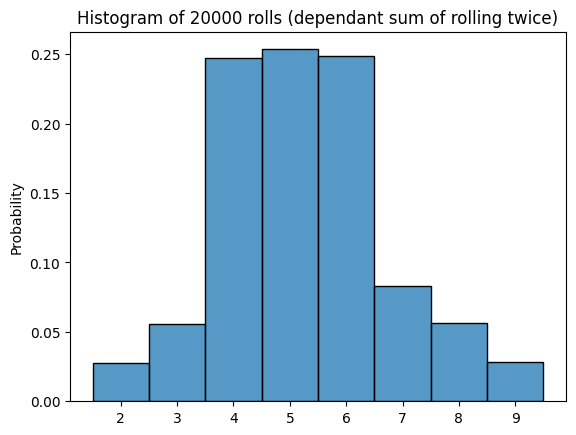

In [40]:
# You can use this cell for your calculations (not graded)
n_rolls = 20000
first_rolls = np.array([np.random.choice(dice) for _ in range(n_rolls)])
second_rolls = np.array([np.random.choice(dice) for _ in range(n_rolls)])
second_rolls = np.where(first_rolls <= 3, second_rolls, 0)
sum_of_rolls = first_rolls + second_rolls

dependant_rolls_hist = sns.histplot(sum_of_rolls, stat="probability", discrete=True)
dependant_rolls_hist.set(
    title=f"Histogram of {n_rolls} rolls (dependant sum of rolling twice)"
)
dependant_rolls_hist.set_xticks(range(min(sum_of_rolls), max(sum_of_rolls) + 1))
plt.show()

In [ ]:
# Run this cell to submit your answer
utils1.exercise_7()

## Exercise 8:

Given the same scenario as in the previous exercise but with the twist that you only throw the dice a second time if the result of the first throw is **greater** or equal to 3. Which of the following `probability mass functions` will be the one you should get given this new constraint?

<table><tr>
<td> <img src="./images/6_sided_cond_green2.png" style="height: 250px;"/> </td>
<td> <img src="./images/6_sided_cond_blue2.png" style="height: 250px;"/> </td>
<td> <img src="./images/6_sided_cond_red2.png" style="height: 250px;"/> </td>
<td> <img src="./images/6_sided_cond_brown2.png" style="height: 250px;"/> </td>

</tr></table>


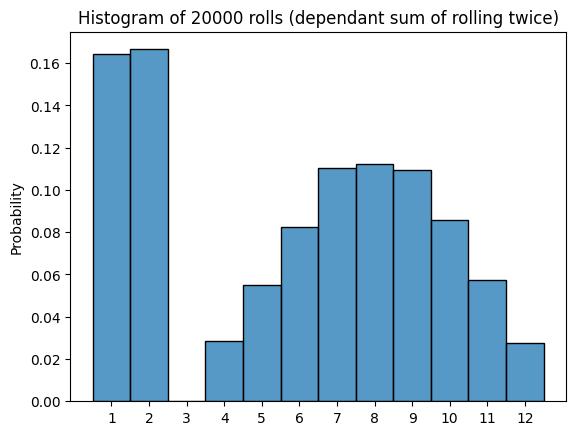

In [41]:
# You can use this cell for your calculations (not graded)
n_rolls = 20000
first_rolls = np.array([np.random.choice(dice) for _ in range(n_rolls)])
second_rolls = np.array([np.random.choice(dice) for _ in range(n_rolls)])
second_rolls = np.where(first_rolls >= 3, second_rolls, 0)
sum_of_rolls = first_rolls + second_rolls

dependant_rolls_hist = sns.histplot(sum_of_rolls, stat="probability", discrete=True)
dependant_rolls_hist.set(
    title=f"Histogram of {n_rolls} rolls (dependant sum of rolling twice)"
)
dependant_rolls_hist.set_xticks(range(min(sum_of_rolls), max(sum_of_rolls) + 1))
plt.show()

In [ ]:
# Run this cell to submit your answer
utils1.exercise_8()

## Exercise 9:

Given a n-sided fair dice. You throw it twice and record the sum. How does increasing the number of sides `n` of the dice impact the mean and variance of the sum and the covariance of the joint distribution?

In [ ]:
# You can use this cell for your calculations (not graded)



In [ ]:
# Run this cell to submit your answer
utils1.exercise_9()

## Exercise 10:

Given a 6-sided loaded dice. You throw it twice and record the sum. Which of the following statemets is true?

In [ ]:
# You can use this cell for your calculations (not graded)



In [ ]:
# Run this cell to submit your answer
utils1.exercise_10()

## Exercise 11:

Given a n-sided dice (could be fair or not). You throw it twice and record the sum (there is no dependance between the throws). If you are only given the histogram of the sums can you use it to know which are the probabilities of the dice landing on each side?

In other words, if you are provided with only the histogram of the sums like this one:
<td> <img src="./images/hist_sum_6_side.png" style="height: 300px;"/> </td>

Could you use it to know the probabilities of the dice landing on each side? Which will be equivalent to finding this histogram:
<img src="./images/fair_dice.png" style="height: 300px;"/>


In [ ]:
# You can use this cell for your calculations (not graded)



In [ ]:
# Run this cell to submit your answer
utils1.exercise_11()

## Before Submitting Your Assignment

Run the next cell to check that you have answered all of the exercises

In [ ]:
utils1.check_submissions()

**Congratulations on finishing this assignment!**

During this assignment you tested your knowledge on probability distributions, descriptive statistics and visual interpretation of these concepts. You had the choice to compute everything analytically or create simulations to assist you get the right answer. You probably also realized that some exercises could be answered without any computations just by looking at certain hidden queues that the visualizations revealed.

**Keep up the good work!**
